In [7]:
import yfinance as yf
import numpy as np
import pandas as pd
from hmmlearn import hmm
from sklearn.preprocessing import StandardScaler
from scipy.stats import multivariate_normal
import matplotlib.pyplot as plt

In [ ]:
# Download the data
features = ['SPY', '^VIX']

start_date = '2007-01-01'
end_date = '2026-09-30'

regime = yf.download(features, start=start_date, end=end_date, auto_adjust=True)
regime = regime['Close']
regime = regime.dropna()
regime 

[*********************100%***********************]  2 of 2 completed


Ticker,SPY,^VIX
Date,,
2007-01-03,98.624588,12.040000
2007-01-04,98.833862,11.510000
2007-01-05,98.045563,12.140000
2007-01-08,98.499016,12.000000
2007-01-09,98.415314,11.910000
...,...,...
2026-09-23,767.809998,15.180000
2026-09-24,767.179993,15.670000
2026-09-25,771.349976,14.870000


(4965, 2) (4965, 3) (4965, 3)
True False
True
True
True
seed 0: train log-likelihood -5948.3, converged True
seed 1: train log-likelihood -5957.9, converged True
seed 2: train log-likelihood -5957.9, converged True
seed 3: train log-likelihood -5957.9, converged True
seed 4: train log-likelihood -5957.9, converged True
seed 5: train log-likelihood -5957.9, converged True
seed 6: train log-likelihood -5957.9, converged True
seed 7: train log-likelihood -5957.9, converged True
seed 8: train log-likelihood -5957.9, converged True
seed 9: train log-likelihood -5957.9, converged True
 checks for the final model 
(4965, 2) (4965, 3) (4965, 3)
True False
True
True
True

Mean VIX and daily SPY return by state (0 = calm, 2 = crisis):
           VIX  SPY_ret
state                  
0      13.6107   0.0008
1      20.2628   0.0002
2      35.7551   0.0001

Share of days in each state:
state      0      1      2
split                     
test   0.447  0.527  0.026
train  0.397  0.434  0.170

Transi

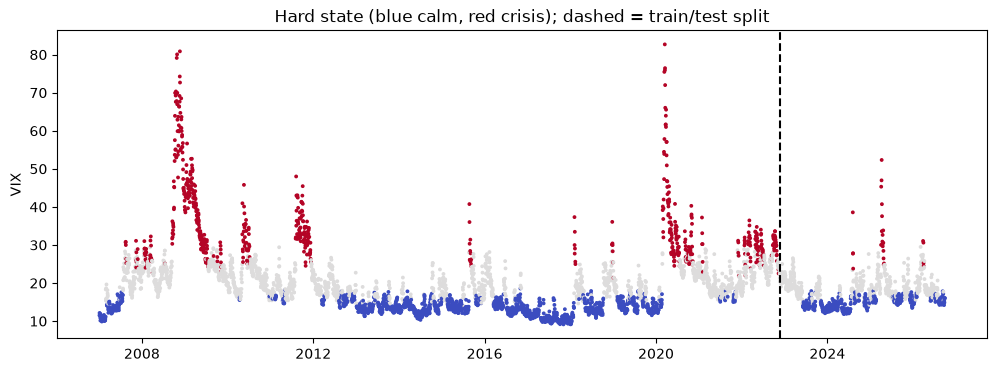

            p_state0       p_state1       p_state2  hard_state  split
Date                                                                 
2007-01-04  1.000000  7.238962e-158  5.155751e-303           0  train
2007-01-05  0.999582   4.183234e-04   2.488122e-14           0  train
2007-01-08  0.999766   2.340406e-04   2.923187e-08           0  train
2007-01-09  0.999833   1.673541e-04   1.560436e-08           0  train
2007-01-10  0.999843   1.572553e-04   1.214026e-08           0  train
            p_state0  p_state1      p_state2  hard_state split
Date                                                          
2026-09-23  0.994780  0.005215  4.707372e-06           0  test
2026-09-24  0.995298  0.004701  1.034517e-06           0  test
2026-09-25  0.996467  0.003532  8.644285e-07           0  test
2026-09-28  0.989692  0.010306  1.986241e-06           0  test
2026-09-29  0.991330  0.008667  2.759828e-06           0  test
(4965, 5) [1.]


In [9]:
# 1. Build the features
regime['SPY_log_returns'] = np.log(regime['SPY'] / regime['SPY'].shift(1))
regime.dropna(inplace=True)

# 2. Split and Scale
feature_cols = ['SPY_log_returns', '^VIX']
X = regime[feature_cols].values

X_train = X[:4000]
X_test = X[4000:]

scaler = StandardScaler()
X_scaled_train = scaler.fit_transform(X_train) 
X_scaled_test = scaler.transform(X_test)
X_scaled = np.vstack([X_scaled_train, X_scaled_test])

# 3. Fit the Hidden Markov Model
model = hmm.GaussianHMM(n_components=3, covariance_type="full", n_iter=200)
model.fit(X_scaled_train)

startprob = model.startprob_ # how likely each state is on day one
transmat = model.transmat_ # how often it switches between states
means = model.means_ # avg of states
covar = model.covars_ # spread of states


# 4. Make a belief for each day
# only looks at yesterday's belief and today's data to avoid data leakage
def filter_beliefs(X_scaled):
    likelihood_table =  np.column_stack([multivariate_normal.logpdf(X_scaled, mean=means[k], cov=covar[k])
            for k in range(3)])

    belief_matrix = np.zeros((len(X_scaled),3))    

    for i in range(len(X_scaled)): # loop over days
        if i == 0:
            prior = startprob
        else:
            prior = np.dot(belief_matrix[i-1], transmat)
        
        log_post = likelihood_table[i] + np.log(prior + 1e-300)
        log_post -= log_post.max()              
        post = np.exp(log_post)
        belief_matrix[i] = post / post.sum() # the three values add to 1

    return likelihood_table, belief_matrix

likelihood_table, belief_matrix = filter_beliefs(X_scaled)

# checks
print(X_scaled.shape, likelihood_table.shape, belief_matrix.shape)   # (n,2) (n,3) (n,3)
print(np.allclose(belief_matrix.sum(axis=1), 1), np.isnan(belief_matrix).any())
print(np.allclose(belief_matrix[-1], model.predict_proba(X_scaled)[-1]))   # last day only
t = 3000
_, b_cut = filter_beliefs(X_scaled[:t+1])
print(np.allclose(belief_matrix[t], b_cut[t]))  # leakage test: must be True
print(model.monitor_.converged)

# 5. fit 10 times from different random starts, keep the best train log-likelihood
best_model, best_score = None, -np.inf
for seed in range(10):
    m = hmm.GaussianHMM(n_components=3, covariance_type="full", n_iter=200, random_state=seed)
    m.fit(X_scaled_train)
    score = m.score(X_scaled_train)
    print(f"seed {seed}: train log-likelihood {score:.1f}, converged {m.monitor_.converged}")
    if score > best_score:
        best_model, best_score = m, score

# the filter above reads these four names, so reassigning them switches it to the best model
model = best_model
startprob = model.startprob_
transmat = model.transmat_
means = model.means_
covar = model.covars_
likelihood_table, belief_matrix = filter_beliefs(X_scaled)

# B. Re-run the checks for the final model
print(" checks for the final model ")
print(X_scaled.shape, likelihood_table.shape, belief_matrix.shape)
print(np.allclose(belief_matrix.sum(axis=1), 1), np.isnan(belief_matrix).any())
print(np.allclose(belief_matrix[-1], model.predict_proba(X_scaled)[-1]))
_, b_cut = filter_beliefs(X_scaled[:t+1])
print(np.allclose(belief_matrix[t], b_cut[t]))        # leakage test: must be True
print(model.monitor_.converged)

# C. Order the states calm -> crisis by each state's mean VIX (real units)
real_means = scaler.inverse_transform(model.means_)   # columns: [SPY_ret, VIX]
order = np.argsort(real_means[:, 1])                  # lowest VIX first
belief_ordered = belief_matrix[:, order]
hard = belief_ordered.argmax(axis=1)
trans_ordered = transmat[np.ix_(order, order)]

# D. Sanity tables
df = pd.DataFrame({'state': hard,
                   'VIX': regime['^VIX'].values,
                   'SPY_ret': regime['SPY_log_returns'].values,
                   'split': np.where(np.arange(len(hard)) < 4000, 'train', 'test')},
                  index=regime.index)
print("\nMean VIX and daily SPY return by state (0 = calm, 2 = crisis):")
print(df.groupby('state')[['VIX', 'SPY_ret']].mean().round(4))
print("\nShare of days in each state:")
print(df.groupby('split')['state'].value_counts(normalize=True).unstack().round(3))
print("\nTransition matrix (ordered), diagonal should be high:")
print(pd.DataFrame(trans_ordered).round(3))
print("\nAvg max probability:", belief_ordered.max(axis=1).mean().round(3))

# E. Plot
plt.figure(figsize=(12, 4))
plt.scatter(df.index, df['VIX'], c=hard, cmap='coolwarm', s=3)
plt.axvline(df.index[4000], color='k', ls='--')
plt.ylabel('VIX'); plt.title('Hard state (blue calm, red crisis); dashed = train/test split')
plt.show()

# F. Regime table: one row per date, for the RL environment
regime_table = pd.DataFrame(belief_ordered, index=regime.index,
                            columns=['p_state0', 'p_state1', 'p_state2'])   # 0 = calm, 2 = crisis
regime_table['hard_state'] = hard
regime_table['split'] = np.where(np.arange(len(regime_table)) < 4000, 'train', 'test')
regime_table.to_csv('regime_states.csv')
print(regime_table.head())
print(regime_table.tail())
print(regime_table.shape, regime_table[['p_state0', 'p_state1', 'p_state2']].sum(axis=1).round(6).unique())

In [4]:
df['state'].value_counts()
df

,state,VIX,SPY_ret,split
Date,,,,
2007-05-31,0,13.050000,-0.001043,train
2007-06-01,0,12.780000,0.004944,train
2007-06-04,0,13.290000,0.000129,train
2007-06-05,0,13.630000,-0.003966,train
2007-06-06,0,14.870000,-0.010808,train
...,...,...,...,...
2026-09-23,0,15.180000,-0.007228,test
2026-09-24,0,15.670000,-0.000821,test
2026-09-25,0,14.870000,0.005421,test


In [5]:
df.groupby(['state'])['SPY_ret'].mean()

state
0    0.000739
1    0.000216
2    0.000042
Name: SPY_ret, dtype: float64